[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/1_uG0memqk_Idj51RvfZ-KtlwQMstgF1X)

<img src="https://raw.githubusercontent.com/richardcsuwandi/gp-time-series-tutorial/main/assets/gp_banner.png" alt="GPyTorch" width="100%">

# Gaussian Processes for Time Series with PyTorch

**CSC6022 tutorial**

In this notebook we fit Gaussian processes (GPs) to real time series using [GPyTorch](https://gpytorch.ai), a GP library built on top of PyTorch. Because everything is a PyTorch module, a GP model is just a small class, training is a normal PyTorch loop, and kernels can be mixed and matched like Lego blocks.

The main message of this tutorial is simple. **The kernel is the model.** The same GP with a different kernel can give a useless forecast or an excellent one, so most of the work goes into designing the right kernel for the data.

**Plan**
1. A short GP recap
2. The GPyTorch building blocks (model, kernels, training loop)
3. Worked example with the Mauna Loa CO$_2$ dataset
4. Your turn with real wireless traffic data from Huawei
5. Can an LLM design the kernel for us?

> **Running on Google Colab.** Use *Runtime → Run all*. Colab already has PyTorch, and the next cell installs GPyTorch.

In [ ]:
%pip install -q gpytorch

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gpytorch
from gpytorch.kernels import RBFKernel, MaternKernel, PeriodicKernel, RQKernel, LinearKernel, ScaleKernel

torch.set_default_dtype(torch.float64)  # GPs are more stable in double precision
torch.manual_seed(0)
plt.rcParams["figure.figsize"] = (11, 3.5)

## 1. A short GP recap

A Gaussian process is a distribution over functions. We write

$$f \sim \mathcal{GP}\big(m(x),\, k(x, x')\big),$$

where $m(x)$ is the mean function (usually a constant) and $k(x, x')$ is the **kernel**, also called the covariance function. The kernel says how similar $f(x)$ and $f(x')$ should be, and this is where all our assumptions about the data live. Is the signal smooth or rough? Does it repeat? Does it have a trend?

We observe noisy data $y_i = f(x_i) + \varepsilon_i$ with $\varepsilon_i \sim \mathcal{N}(0, \sigma^2)$.

**Training.** The kernel has hyperparameters $\theta$ (lengthscales, periods, variances). We learn them by maximizing the log marginal likelihood

$$\log p(\mathbf{y} \mid X, \theta) = -\tfrac{1}{2}\mathbf{y}^\top (K_\theta + \sigma^2 I)^{-1}\mathbf{y} - \tfrac{1}{2}\log\lvert K_\theta + \sigma^2 I\rvert - \tfrac{n}{2}\log 2\pi .$$

The first term rewards fitting the data and the second term penalizes overly complex models. In PyTorch this is just a loss we minimize with gradient descent.

**Prediction.** Given the training data, the prediction at new inputs is again Gaussian, so every forecast comes with an uncertainty band for free.

## 2. GPyTorch building blocks

### 2.1 The model

A GPyTorch model is a PyTorch module with a mean and a kernel. We pass the kernel in as an argument, so that trying a new kernel is a one-line change.

In [3]:
class GPModel(gpytorch.models.ExactGP):
    def __init__(self, train_x, train_y, kernel):
        likelihood = gpytorch.likelihoods.GaussianLikelihood()  # learns the noise variance
        super().__init__(train_x, train_y, likelihood)
        self.mean_module = gpytorch.means.ConstantMean()
        self.covar_module = kernel

    def forward(self, x):
        mean = self.mean_module(x)
        covar = self.covar_module(x)
        return gpytorch.distributions.MultivariateNormal(mean, covar)

### 2.2 Kernels

GPyTorch ships with the classic kernels, and you combine them with `+` and `*`.

| Kernel | Assumption about the function |
|---|---|
| `RBFKernel` | very smooth, varies on a length scale $\ell$ |
| `MaternKernel(nu=0.5, 1.5, 2.5)` | smooth but rougher than RBF (smaller `nu` means rougher) |
| `PeriodicKernel` | repeats exactly every `period_length` |
| `RQKernel` | mixture of many length scales |
| `LinearKernel` | linear trend |
| `ScaleKernel(k)` | wraps `k` and learns its overall variance (outputscale) |

The rules for combining them are intuitive.
* **Sum** `k1 + k2` means the function is a sum of two independent parts (for example trend plus seasonality).
* **Product** `k1 * k2` means one behavior modulates the other (for example a periodic pattern whose shape slowly changes over time).

The quickest way to understand a kernel is to draw random functions from the prior. You can set initial hyperparameters with `.initialize(...)`.

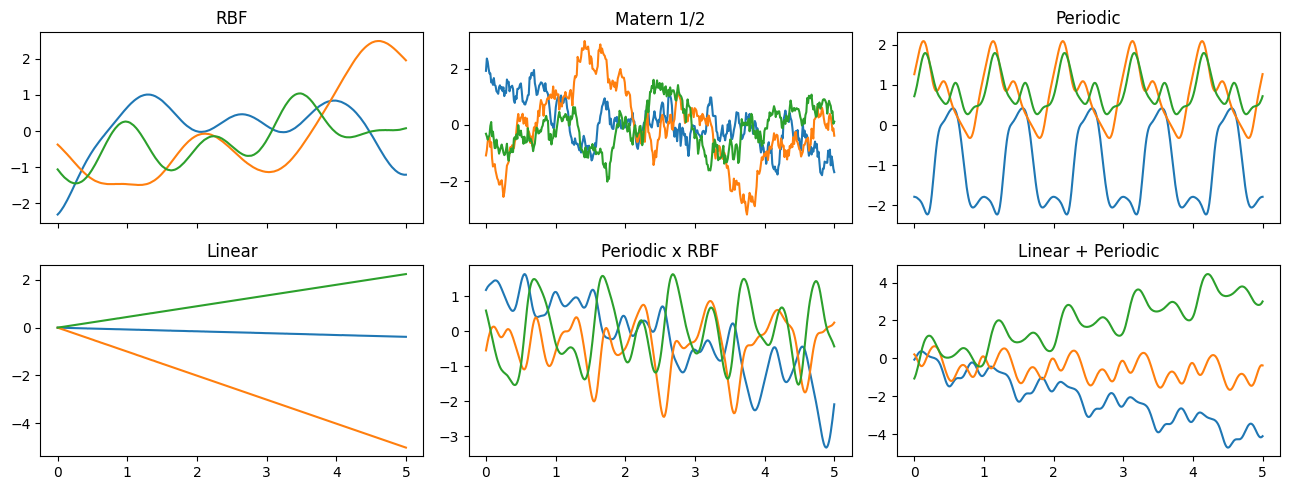

In [4]:
x_grid = torch.linspace(0, 5, 400)
prior_kernels = {
    "RBF": RBFKernel().initialize(lengthscale=0.5),
    "Matern 1/2": MaternKernel(nu=0.5).initialize(lengthscale=0.5),
    "Periodic": PeriodicKernel().initialize(period_length=1.0),
    "Linear": LinearKernel(),
    "Periodic x RBF": PeriodicKernel().initialize(period_length=1.0) * RBFKernel().initialize(lengthscale=2.0),
    "Linear + Periodic": LinearKernel() + PeriodicKernel().initialize(period_length=1.0),
}

fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharex=True)
for ax, (name, k) in zip(axes.flat, prior_kernels.items()):
    with torch.no_grad():
        K = k(x_grid).to_dense() + 1e-6 * torch.eye(len(x_grid))
        samples = gpytorch.distributions.MultivariateNormal(torch.zeros(len(x_grid)), K).sample(torch.Size([3]))
    ax.plot(x_grid, samples.T)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### 2.3 Training and prediction

Training is a standard PyTorch loop. The loss is the negative marginal likelihood (GPyTorch divides it by the number of points, so the numbers stay small).

In [5]:
def train(model, iters=300, lr=0.05):
    x, y = model.train_inputs[0], model.train_targets
    mll = gpytorch.mlls.ExactMarginalLogLikelihood(model.likelihood, model)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for i in range(iters):
        optimizer.zero_grad()
        loss = -mll(model(x), y)
        loss.backward()
        optimizer.step()
        if i % 100 == 0 or i == iters - 1:
            print(f"iter {i:4d}   loss {loss.item():.3f}")
    return model


def predict(model, x):
    model.eval()
    with torch.no_grad():
        pred = model.likelihood(model(x))  # includes observation noise
    return pred.mean, pred.variance.sqrt()


def score(model, x_test, y_test):
    # RMSE checks the mean, NLPD (negative log predictive density) also checks the uncertainty. Lower is better for both.
    mean, std = predict(model, x_test)
    rmse = (mean - y_test).pow(2).mean().sqrt().item()
    nlpd = -torch.distributions.Normal(mean, std).log_prob(y_test).mean().item()
    return rmse, nlpd


def plot_fit(model, x_train, y_train, x_test, y_test, title="", y_mean=0.0, y_std=1.0, xlabel="x", ylabel="y"):
    x_all = torch.cat([x_train, x_test])
    mean, std = predict(model, x_all)
    un = lambda v: v * y_std + y_mean  # undo standardization for plotting
    plt.figure()
    plt.plot(x_train, un(y_train), "k.", ms=2, label="train")
    plt.plot(x_test, un(y_test), ".", color="tab:red", ms=2, label="test")
    plt.plot(x_all, un(mean), color="tab:blue", label="GP mean")
    plt.fill_between(x_all, un(mean - 2 * std), un(mean + 2 * std), color="tab:blue", alpha=0.2, label="±2 std")
    plt.axvline(x_test[0].item(), color="gray", ls="--")
    rmse, nlpd = score(model, x_test, y_test)
    plt.title(f"{title}   (test RMSE {rmse:.3f}, NLPD {nlpd:.3f})")
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(loc="upper left")
    plt.show()

## 3. Worked example with Mauna Loa CO$_2$

This dataset contains monthly atmospheric CO$_2$ measurements at the Mauna Loa Observatory in Hawaii from 1958 to 2001. It is the classic example for kernel design (see the [scikit-learn version](https://scikit-learn.org/stable/auto_examples/gaussian_process/plot_gpr_co2.html) of this example). We train on data before 1990 and ask the GP to **forecast** the following 12 years.

377 training months, 144 test months


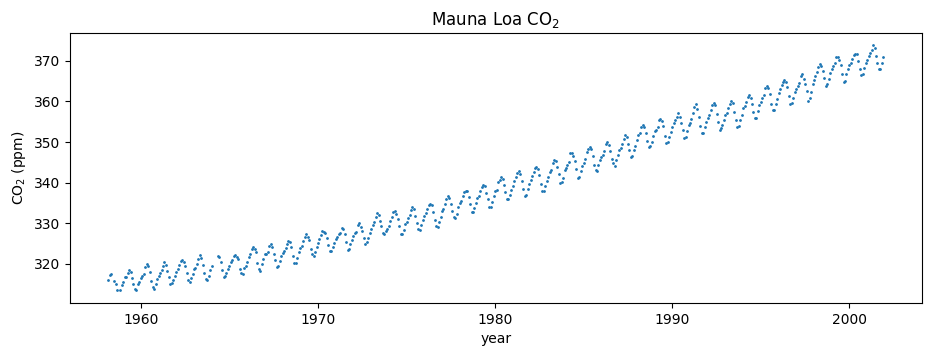

In [6]:
from sklearn.datasets import fetch_openml

co2 = fetch_openml(data_id=41187, as_frame=True).frame
monthly = co2.groupby(["year", "month"])["co2"].mean().reset_index()
years = (monthly["year"] + (monthly["month"] - 1) / 12).to_numpy()

x = torch.tensor(years - 1958.0)  # input = years since 1958
y_raw = torch.tensor(monthly["co2"].to_numpy())

train_mask = years < 1990
y_mean, y_std = y_raw[train_mask].mean(), y_raw[train_mask].std()
y = (y_raw - y_mean) / y_std  # standardize the targets, which makes optimization easier

x_train, y_train = x[train_mask], y[train_mask]
x_test, y_test = x[~train_mask], y[~train_mask]
print(f"{len(x_train)} training months, {len(x_test)} test months")

plt.plot(years, y_raw, ".", ms=2)
plt.xlabel("year")
plt.ylabel("CO$_2$ (ppm)")
plt.title("Mauna Loa CO$_2$")
plt.show()

Look at the data before choosing a kernel. There is a **smooth rising trend**, a **yearly seasonal cycle**, and some **small irregular wiggles**.

### Attempt 1. A plain RBF kernel

Let us first try the default choice that many people use without thinking.

iter    0   loss 0.904


iter  100   loss -0.224


iter  200   loss -0.242


iter  299   loss -0.247


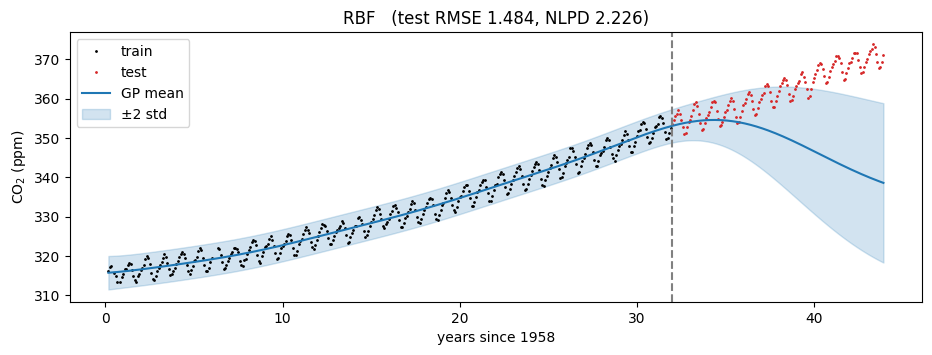

In [7]:
model_rbf = train(GPModel(x_train, y_train, ScaleKernel(RBFKernel())))
plot_fit(model_rbf, x_train, y_train, x_test, y_test, "RBF", y_mean, y_std, "years since 1958", "CO$_2$ (ppm)")

The RBF kernel fits the training data, but the forecast quickly falls back to the mean. An RBF kernel only knows that nearby points are similar, so it has no idea that the trend continues or that the seasons repeat.

### Attempt 2. A kernel designed from what we see

We build one kernel component for each pattern we identified, and initialize the hyperparameters with sensible values in units of years.

* **Trend.** A long-lengthscale RBF (about 50 years).
* **Seasonality.** A periodic kernel with period 1 year, multiplied by a long RBF so the shape of the seasonal cycle can slowly change.
* **Irregularities.** A rational quadratic kernel for medium-term wiggles.
* **Noise.** Learned by the Gaussian likelihood.

iter    0   loss 0.876


iter  100   loss -1.486


iter  200   loss -1.543


iter  299   loss -2.175


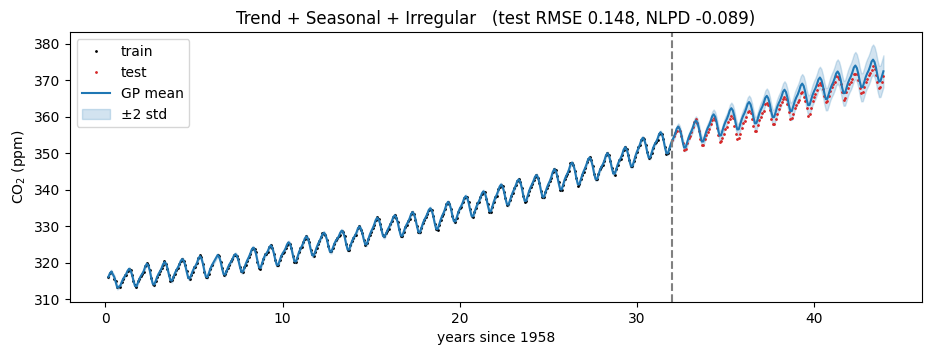

In [8]:
trend = ScaleKernel(RBFKernel().initialize(lengthscale=50.0))
seasonal = ScaleKernel(PeriodicKernel().initialize(period_length=1.0) * RBFKernel().initialize(lengthscale=100.0))
irregular = ScaleKernel(RQKernel().initialize(lengthscale=1.0, alpha=1.0))

model_co2 = train(GPModel(x_train, y_train, trend + seasonal + irregular))
plot_fit(model_co2, x_train, y_train, x_test, y_test, "Trend + Seasonal + Irregular", y_mean, y_std, "years since 1958", "CO$_2$ (ppm)")

The forecast now follows both the trend and the seasonal cycle for more than a decade, and the uncertainty band grows as we move further from the data.

The learned hyperparameters are interpretable, which is one of the nicest things about GPs.

In [9]:
k_trend, k_seasonal, k_irregular = model_co2.covar_module.kernels
print(f"trend lengthscale     {k_trend.base_kernel.lengthscale.item():6.1f} years")
print(f"seasonal period       {k_seasonal.base_kernel.kernels[0].period_length.item():6.2f} years")
print(f"seasonal decay        {k_seasonal.base_kernel.kernels[1].lengthscale.item():6.1f} years")
print(f"irregular lengthscale {k_irregular.base_kernel.lengthscale.item():6.2f} years")
print(f"noise std             {model_co2.likelihood.noise.sqrt().item() * y_std.item():6.3f} ppm")

trend lengthscale       41.1 years
seasonal period         1.00 years
seasonal decay          95.1 years
irregular lengthscale   2.12 years
noise std              0.205 ppm


Here is a side-by-side comparison, including a middle ground with only trend and periodicity. Same data, same model class, same training loop. **Only the kernel changes.**

In [10]:
model_mid = train(GPModel(x_train, y_train,
                          ScaleKernel(RBFKernel().initialize(lengthscale=50.0))
                          + ScaleKernel(PeriodicKernel().initialize(period_length=1.0))), iters=300)

results = {
    "RBF": score(model_rbf, x_test, y_test),
    "RBF + Periodic": score(model_mid, x_test, y_test),
    "Trend + Seasonal + Irregular": score(model_co2, x_test, y_test),
}
pd.DataFrame(results, index=["test RMSE", "test NLPD"]).T.round(3)

iter    0   loss 0.841


iter  100   loss -0.279


iter  200   loss -0.286


iter  299   loss -0.288


,test RMSE,test NLPD
RBF,1.484,2.226
RBF + Periodic,0.226,-0.023
Trend + Seasonal + Irregular,0.148,-0.089


### Writing your own kernel

Because GPyTorch is PyTorch, a new kernel is just a class with a `forward` method that returns the covariance matrix. Here is the RBF kernel written from scratch in a few lines. Anything you can write in PyTorch (as long as it gives a valid covariance) can become a kernel. Keep this in mind for Section 5.

In [11]:
class MyRBF(gpytorch.kernels.Kernel):
    has_lengthscale = True  # GPyTorch creates and constrains self.lengthscale for us

    def forward(self, x1, x2, **params):
        sqdist = self.covar_dist(x1 / self.lengthscale, x2 / self.lengthscale, square_dist=True, **params)
        return torch.exp(-0.5 * sqdist)


# It plugs in exactly like a built-in kernel and should match the RBF result above
model_my = train(GPModel(x_train, y_train, ScaleKernel(MyRBF())))
rmse, nlpd = score(model_my, x_test, y_test)
print(f"MyRBF   test RMSE {rmse:.3f}, NLPD {nlpd:.3f}")

iter    0   loss 0.904


iter  100   loss -0.224


iter  200   loss -0.242


iter  299   loss -0.247
MyRBF   test RMSE 1.484, NLPD 2.226


## 4. Your turn with Huawei wireless traffic

Now we switch to a real industrial dataset. It contains **uplink traffic** from 30 anonymized wireless network cells, recorded every **5 minutes** for **7 days** (2024-11-30 to 2024-12-07).

The data is loaded directly from the [tutorial repository](https://github.com/richardcsuwandi/gp-time-series-tutorial), and the preprocessing is done for you.
* We average to 15-minute resolution to keep things fast.
* Traffic is heavy-tailed and always positive, so we model **log traffic**.
* The input $x$ is measured in **days**, so a period of 1 means one day.
* We train on the first 6 days and forecast the last day.

576 training points, 97 test points


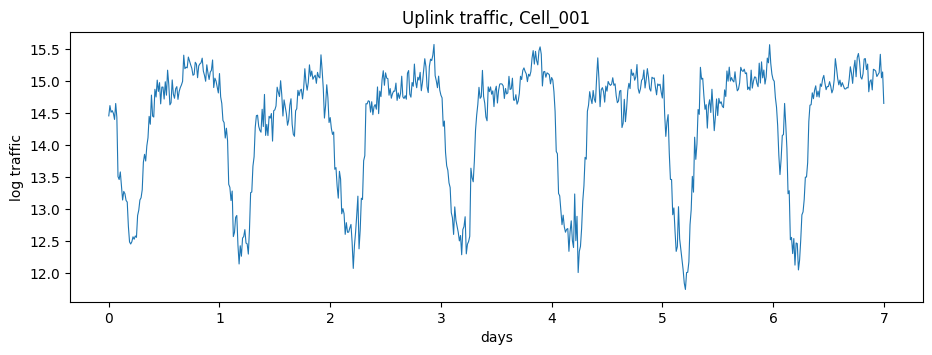

In [12]:
DATA_URL = "https://raw.githubusercontent.com/richardcsuwandi/gp-time-series-tutorial/main/huawei_cell_traffic.csv"
CELL = "Cell_001"  # try other cells too, from Cell_001 to Cell_030

traffic = pd.read_csv(DATA_URL, parse_dates=["timestamp"]).set_index("timestamp")
series = traffic[CELL].resample("15min").mean()

days = (series.index - series.index[0]).total_seconds().to_numpy() / 86400
hx = torch.tensor(days)
hy_raw = torch.tensor(np.log(series.to_numpy()))

h_train_mask = days < 6
hy_mean, hy_std = hy_raw[h_train_mask].mean(), hy_raw[h_train_mask].std()
hy = (hy_raw - hy_mean) / hy_std

hx_train, hy_train = hx[h_train_mask], hy[h_train_mask]
hx_test, hy_test = hx[~h_train_mask], hy[~h_train_mask]
print(f"{len(hx_train)} training points, {len(hx_test)} test points")

plt.plot(days, hy_raw, lw=0.8)
plt.xlabel("days")
plt.ylabel("log traffic")
plt.title(f"Uplink traffic, {CELL}")
plt.show()

### Baseline

Here is the plain RBF kernel again.

iter    0   loss 1.415


iter  100   loss 0.124


iter  200   loss 0.120


iter  299   loss 0.120


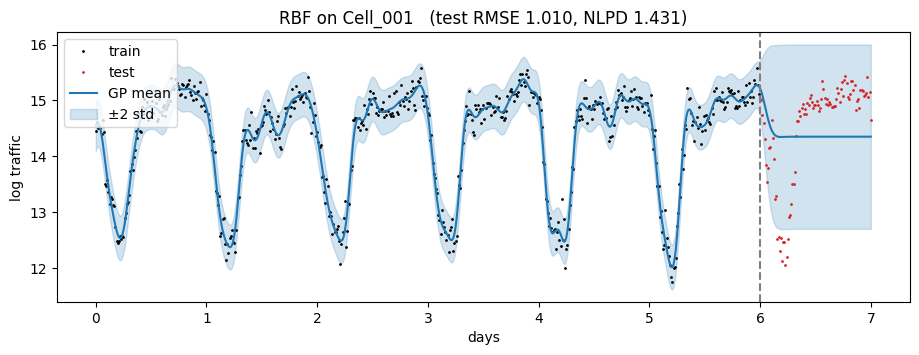

In [13]:
model_h_rbf = train(GPModel(hx_train, hy_train, ScaleKernel(RBFKernel())))
plot_fit(model_h_rbf, hx_train, hy_train, hx_test, hy_test, f"RBF on {CELL}", hy_mean, hy_std, "days", "log traffic")

### ✏️ Exercise. Design a better kernel

The RBF forecast for day 7 is basically flat. Your job is to replace it with a kernel that captures the structure of this data. Some questions to guide you.

1. Look at the plot. What pattern repeats, and how often? What is that period in units of $x$?
2. Is every day exactly the same, or does the daily shape change a bit? Which kernel operation lets a pattern slowly change?
3. Is there short-term fluctuation on top of the daily pattern? Is it smooth or rough?
4. Remember to give periods and lengthscales sensible initial values with `.initialize(...)`.

Edit `my_kernel()` below and run the next two cells. Try to beat the RBF baseline on both RMSE and NLPD.

iter    0   loss 1.415


iter  100   loss 0.124


iter  200   loss 0.120


iter  299   loss 0.120


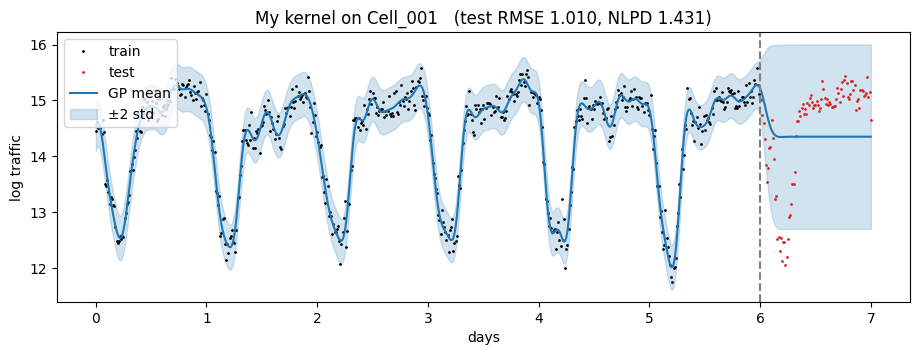

In [14]:
def my_kernel():
    # TODO: replace this baseline with your own kernel design
    return ScaleKernel(RBFKernel())


model_h = train(GPModel(hx_train, hy_train, my_kernel()))
plot_fit(model_h, hx_train, hy_train, hx_test, hy_test, f"My kernel on {CELL}", hy_mean, hy_std, "days", "log traffic")

In [15]:
pd.DataFrame({
    "RBF baseline": score(model_h_rbf, hx_test, hy_test),
    "My kernel": score(model_h, hx_test, hy_test),
}, index=["test RMSE", "test NLPD"]).T.round(3)

,test RMSE,test NLPD
RBF baseline,1.01,1.431
My kernel,1.01,1.431


**Things to try after that**
* Run your kernel on a few other cells. Does one kernel work well for all of them?
* Compare `MaternKernel(nu=0.5)`, `nu=1.5` and `RBFKernel` for the short-term part.
* What happens if you model raw traffic instead of log traffic?

<details>
<summary><b>Show one possible solution</b> (try it yourself first)</summary>

A daily periodic kernel plus a rough Matérn kernel for short-term fluctuations works well for most cells.

```python
def my_kernel():
    daily = ScaleKernel(PeriodicKernel().initialize(period_length=1.0))
    short_term = ScaleKernel(MaternKernel(nu=0.5).initialize(lengthscale=0.05))
    return daily + short_term
```

On `Cell_001` this cuts the test RMSE from about 1.0 to about 0.4. Notice that it took several design decisions (which components, how to combine them, how to initialize them) and that the best choice can differ from cell to cell.
</details>

## 5. Can an LLM design the kernel for us?

You have now seen that the kernel decides whether a GP works or fails, and that designing it by hand takes domain knowledge, trial and error, and a good feel for kernel algebra. With 30 cells (or 3,000), doing this by hand for every series does not scale. In two recent papers, we hand this job to large language models.

### CAKE. LLM-driven kernel evolution

*Adaptive Kernel Design for Bayesian Optimization Is a Piece of CAKE with LLMs* (NeurIPS 2025)
[Paper (arXiv)](https://arxiv.org/abs/2509.17998) · [Code (GitHub)](https://github.com/richardcsuwandi/cake)

![CAKE overview](https://raw.githubusercontent.com/richardcsuwandi/cake/main/assets/cake.png)

CAKE keeps a population of kernel expressions built from the same blocks you used above (SE, PER, LIN, RQ, Matérn) and asks an LLM to cross over and mutate them, keeping the ones that fit the data best. It automates exactly the "try a sum, try a product, check the fit" loop that you just did by hand.

### Kernaut. Coding agents write kernels as programs

*Kernel Autoresearch for Open-Ended Model Discovery*
[Paper (arXiv)](https://arxiv.org/abs/2610.10394) · [Code (GitHub)](https://github.com/richardcsuwandi/kernaut) · [Docs](https://richardcsuwandi.github.io/kernaut/)

![Kernaut overview](https://raw.githubusercontent.com/richardcsuwandi/kernaut/main/assets/method-overview.png)

Kernaut goes beyond fixed building blocks. A coding agent writes new kernels as PyTorch programs (like the `MyRBF` class in Section 3), a verification backend checks that each one is a valid kernel, and an archive keeps strong and diverse kernels. This means it can discover kernels that no fixed grammar contains.

**Want to try it?** Both repositories are open source. A good mini-project is to point one of them at the Huawei traffic data and compare the discovered kernel with the one you designed in Section 4.